# COMP8410 Assignment 1 — Advanced AI Model Evaluation

**Organisation:** Adobe Inc.  
**Application:** Adobe Express  
**Student ID:** 48930164
**Github Link:** https://github.com/Sagun-Mq/COMP8410_Assignment_1

## Project Overview

This assignment evaluates two proposed AI systems for Adobe Express, focusing on the application of advanced artificial intelligence techniques to creative design and content production.

The study compares four pairs of AI models across four tasks: image–text retrieval, generative image editing, multimodal visual understanding, and agentic content generation.

Each pair represents two competing approaches to the same task. The models are evaluated independently using suitable datasets, consistent experimental conditions, quantitative metrics, qualitative observations, and analysis of their underlying AI techniques.

The experiments aim to determine not only which models achieve better performance, but also why their architectures differ, how reliably they perform, and whether they offer practical benefits for Adobe Express.

### Proposed AI Systems

- **System A:** MetaCLIP 2, Qwen-Image-Edit-2511, Qwen3-VL, and Qwen3.
- **System B:** SigLIP 2, FLUX.2 Klein, Gemma 4, and Llama 3.1 8B Instruct.

These represent hypothetical alternatives for Adobe Express rather than claims about Adobe's existing internal systems.

### Evaluation Approach

Each experiment follows a common methodology:

1. Define the business objective and research question.
2. Select and examine an appropriate benchmark dataset.
3. Establish evaluation metrics and a baseline.
4. Evaluate both models under comparable conditions.
5. Analyse quantitative results and qualitative failures.
6. Investigate possible improvements.
7. Assess business suitability, governance, and limitations.
8. Provide a justified model recommendation.

The four experiments are documented in separate Jupyter notebooks, with the overall findings consolidated in a unified evaluation report.

The evaluation emphasises AI modelling and technical evidence rather than general software implementation. Models are compared within their respective tasks; performance scores from unrelated tasks are not directly ranked against one another.

## Experiment 1 - Image-Text Retrieval


Adobe Express supports the creation of promotional content, presentations, and digital designs. An intelligent asset retrieval system could help users locate relevant images using natural-language descriptions.

This experiment investigates whether recent vision-language representation models can improve the accuracy and efficiency of semantic image retrieval.

### 1.2 Selected Models

**Model A — MetaCLIP 2**
- Checkpoint: `facebook/metaclip-2-worldwide-b16`
- Technique: Contrastive image–text representation learning.

**Model B — SigLIP 2 Large**
- Checkpoint: `google/siglip2-large-patch16-256`
- Technique: Sigmoid-based image–text alignment and representation learning.

Both models encode images and text into feature representations that can be compared to rank images according to their relevance to a query.

### 1.3 Research Question

Which model provides more accurate semantic image retrieval while maintaining reasonable computational efficiency?



### Dataset Selection - Flickr8k

**Source:** https://huggingface.co/datasets/intro/flickr8k

Flickr8k contains 8,000 photographs, each associated with five human-written captions. The known image–caption relationships provide ground truth for evaluating semantic image retrieval.

The dataset was selected because it supports standard retrieval metrics, including Recall@1, Recall@5, and Recall@10, and provides predefined training, development, and test splits.

The development split will be used to establish the evaluation procedure, while the held-out test split will be reserved for the final comparison.

Although the images are general photographs rather than professional design assets, the dataset offers a reproducible benchmark for an image-search capability relevant to Adobe Express.

In [2]:
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset
from PIL import Image
from IPython.display import display

# Shared random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Inference device
device = "mps" if torch.backends.mps.is_available() else "cpu"

/opt/anaconda3/envs/comp8410-adobe/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import os

# Bypass the Xet download mechanism that caused the error.
os.environ["HF_HUB_DISABLE_XET"] = "1"

from datasets import load_dataset
import pandas as pd
from IPython.display import display

# Load only the development and test splits from Parquet files.
base_url = (
    "https://huggingface.co/datasets/intro/flickr8k/"
    "resolve/refs%2Fconvert%2Fparquet/default"
)

flickr8k = load_dataset(
    "parquet",
    data_files={
        "dev": f"{base_url}/dev/0000.parquet",
        "test": f"{base_url}/test/0000.parquet"
    }
)

dev_data = flickr8k["dev"]
test_data = flickr8k["test"]

split_summary = pd.DataFrame({
    "Split": ["Development", "Test"],
    "Images": [len(dev_data), len(test_data)]
})

display(split_summary)
print("Dataset columns:", dev_data.column_names)

,Split,Images
0,Development,1000
1,Test,1000


Dataset columns: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']


### Ground-Truth Preparation

The Flickr8k development split contains 1,000 images, each associated
with five human-written captions.

For text-to-image retrieval, each caption is treated as an independent
text query, while its corresponding image is the ground-truth match.

This produces 5,000 text queries and 1,000 candidate images.

Both MetaCLIP 2 and SigLIP 2 will rank the same candidate images for
each query. Retrieval accuracy will be measured using Recall@1,
Recall@5, and Recall@10.

The development split is used to establish the evaluation methodology.
The test split is reserved for the final independent comparison.

In [4]:
# Prepare ground-truth text queries from the development split.

dev_queries = pd.DataFrame([
    {
        "image_id": image_id,
        "caption_id": caption_id,
        "query": caption
    }
    for caption_id in range(5)
    for image_id, caption in enumerate(
        dev_data[f"caption_{caption_id}"]
    )
])

print(f"Candidate images: {len(dev_data):,}")
print(f"Text queries: {len(dev_queries):,}")
print(f"Unique ground-truth images: {dev_queries['image_id'].nunique():,}")

display(dev_queries.head(10))

Candidate images: 1,000
Text queries: 5,000
Unique ground-truth images: 1,000


,image_id,caption_id,query
0,0,0,A child and a woman are at waters edge in a bi...
1,1,0,A boy with a stick kneeling in front of a goal...
2,2,0,A woman crouches near three dogs in a field .
3,3,0,A boy bites hard into a treat while he sits ou...
4,4,0,A person eats takeout while watching a small t...
5,5,0,The children are playing in the water .
6,6,0,A group of eight people are gathered around a ...
7,7,0,A boy in blue shorts slides down a slide into ...
8,8,0,A man in a wetsuit is throwing a baby wearing ...
9,9,0,A family playing on a tractor on a beautiful day


### Evaluation Metrics and Baseline

The experiment evaluates text-to-image retrieval using three standard metrics:

- **Recall@1 (R@1):** Percentage of queries where the correct image is ranked first.
- **Recall@5 (R@5):** Percentage of queries where the correct image appears among the top five results.
- **Recall@10 (R@10):** Percentage of queries where the correct image appears among the top ten results.

Higher Recall@K indicates better retrieval performance.

A random-ranking baseline is established to provide a reference for the two pretrained models.

With 1,000 candidate images, the expected random Recall@1, Recall@5, and Recall@10 values are 0.1%, 0.5%, and 1.0%, respectively.

Both models will use the same queries, candidate images, ground-truth identifiers, and evaluation metrics. Inference time will also be recorded to compare computational efficiency.

The development split is used for methodology development, while the test split is reserved for the final evaluation.


In [5]:

def evaluate_retrieval(scores, ground_truth, ks=(1, 5, 10)):
    """
    Evaluate text-to-image retrieval.

    scores: similarity matrix [number of queries, number of images]
    ground_truth: correct image ID for each query
    """
    ground_truth = np.asarray(ground_truth)
    max_k = max(ks)

    # Rank candidate images by descending similarity.
    ranked_images = np.argsort(-scores, axis=1)[:, :max_k]

    results = {}

    for k in ks:
        correct = (
            ranked_images[:, :k] == ground_truth[:, None]
        ).any(axis=1)

        results[f"Recall@{k}"] = correct.mean() * 100

    return results


# Random-retrieval baseline
rng = np.random.default_rng(42)

random_scores = rng.random(
    (len(dev_queries), len(dev_data)),
    dtype=np.float32
)

ground_truth = dev_queries["image_id"].to_numpy()

baseline_results = evaluate_retrieval(
    random_scores,
    ground_truth
)

print("Random Retrieval Baseline")
for metric, value in baseline_results.items():
    print(f"{metric}: {value:.2f}%")

Random Retrieval Baseline
Recall@1: 0.02%
Recall@5: 0.64%
Recall@10: 1.36%


### Model A - MetaCLIP 2

**Model:** MetaCLIP 2 Worldwide ViT-B/16  
**Checkpoint:** `facebook/metaclip-2-worldwide-b16`

MetaCLIP 2 is a vision-language model developed by Meta. It uses contrastive learning to align image and text representations in a shared embedding space.

The model uses separate vision and text encoders to generate embeddings, allowing semantic similarity to be calculated between an image and a written description.

**Evaluation objective:** Measure how accurately MetaCLIP 2 retrieves the correct Flickr8k image for each text query.

The pretrained model is evaluated without fine-tuning. Its performance will be compared against the random baseline and SigLIP 2 using identical evaluation data.

**Governance consideration:** The selected checkpoint has a CC BY-NC 4.0 licence, which restricts commercial use.

In [6]:
from transformers import AutoProcessor, AutoModel

MODEL_A_ID = "facebook/metaclip-2-worldwide-b16"

# Download and load the pretrained model
metaclip_processor = AutoProcessor.from_pretrained(MODEL_A_ID)
metaclip_model = AutoModel.from_pretrained(MODEL_A_ID).to(device)

metaclip_model.eval()

print("MetaCLIP 2 loaded successfully.")

W1103 02:36:02.765000 89758 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 8302.17it/s]


MetaCLIP 2 loaded successfully.


### MetaCLIP 2 - Image Feature Extraction

MetaCLIP 2 converts images into numerical feature vectors called embeddings. These embeddings represent visual information in a shared image–text feature space.

The 1,000 Flickr8k development images are processed in batches to manage memory usage.

Each embedding is normalised before similarity calculation, allowing cosine similarity to be computed using the dot product. The extracted embeddings are normalised and retained in memory for subsequent retrieval evaluation.

The same evaluation procedure will later be applied to SigLIP 2.

In [7]:
# Extract MetaCLIP 2 image embeddings

batch_size = 16
embeddings = []

for start in range(0, len(dev_data), batch_size):
    end = min(start + batch_size, len(dev_data))

    images = [
        dev_data[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    inputs = metaclip_processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = metaclip_model.get_image_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 128 == 0 or end == len(dev_data):
        print(f"Processed {end:,}/{len(dev_data):,} images")

image_embeddings = np.concatenate(embeddings, axis=0)

print("\nMetaCLIP 2 image feature extraction complete.")
print("Embedding shape:", image_embeddings.shape)

Processed 128/1,000 images
Processed 256/1,000 images
Processed 384/1,000 images
Processed 512/1,000 images
Processed 640/1,000 images
Processed 768/1,000 images
Processed 896/1,000 images
Processed 1,000/1,000 images

MetaCLIP 2 image feature extraction complete.
Embedding shape: (1000, 512)


### MetaCLIP 2 - Text Feature Extraction

The 5,000 Flickr8k development captions are converted into text embeddings using MetaCLIP 2's pretrained text encoder.

Each embedding is normalised to support cosine similarity calculation with the previously extracted image embeddings.

Captions are processed in batches, and their normalised embeddings are retained in memory for retrieval evaluation. The resulting image and text embeddings will be used to rank candidate images and calculate retrieval performance.


In [8]:
# Extract MetaCLIP 2 text embeddings

batch_size = 64
captions = dev_queries["query"].tolist()
embeddings = []

for start in range(0, len(captions), batch_size):
    end = min(start + batch_size, len(captions))

    inputs = metaclip_processor(
        text=captions[start:end],
        padding=True,
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = metaclip_model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 640 == 0 or end == len(captions):
        print(f"Processed {end:,}/{len(captions):,} captions")

text_embeddings = np.concatenate(embeddings, axis=0)

print("\nMetaCLIP 2 text feature extraction complete.")
print("Embedding shape:", text_embeddings.shape)

Processed 640/5,000 captions
Processed 1,280/5,000 captions
Processed 1,920/5,000 captions
Processed 2,560/5,000 captions
Processed 3,200/5,000 captions
Processed 3,840/5,000 captions
Processed 4,480/5,000 captions
Processed 5,000/5,000 captions

MetaCLIP 2 text feature extraction complete.
Embedding shape: (5000, 512)


### MetaCLIP 2 - Retrieval Evaluation

The image and text embeddings are compared using cosine similarity. Since both sets of embeddings have already been normalised, their dot product provides the similarity scores.

For each of the 5,000 text queries, the model ranks all 1,000 candidate images based on similarity.

Retrieval performance is evaluated using Recall@1, Recall@5, and Recall@10 and compared against the random baseline.

These development-set results provide an initial measurement of MetaCLIP 2's retrieval performance. The held-out test set will be used for the final evaluation.

In [9]:
# Calculate similarity between captions and images
similarity_scores = text_embeddings @ image_embeddings.T

# Evaluate retrieval accuracy
metaclip_results = evaluate_retrieval(
    similarity_scores,
    ground_truth
)

# Display results
print("MetaCLIP 2 — Development Results")
print("-" * 35)

for metric in ["Recall@1", "Recall@5", "Recall@10"]:
    print(f"{metric}: {metaclip_results[metric]:.2f}% "
          f"(Random: {baseline_results[metric]:.2f}%)")

# Display evaluation results
metaclip_df = pd.DataFrame([{
    "Model": "MetaCLIP 2",
    **metaclip_results
}])

display(metaclip_df)

MetaCLIP 2 — Development Results
-----------------------------------
Recall@1: 62.72% (Random: 0.02%)
Recall@5: 87.00% (Random: 0.64%)
Recall@10: 93.02% (Random: 1.36%)


,Model,Recall@1,Recall@5,Recall@10
0,MetaCLIP 2,62.72,87.0,93.02


### Initial Results and Interpretation

MetaCLIP 2 achieved Recall@1 of 62.72%, Recall@5 of 87.00%, and Recall@10 of 93.02% on 5,000 Flickr8k development queries against 1,000 candidate images.

Performance substantially exceeded the random-ranking baseline, demonstrating that the model learned useful image–text relationships.

However, 37.28% of queries did not retrieve the correct image at rank one. Further error analysis is needed to identify difficult descriptions, ambiguous images, and potential retrieval limitations.

These findings are preliminary. The final model comparison will use the held-out test split and identical evaluation settings for SigLIP 2.


### Model B - SigLIP 2

**Model:** SigLIP 2 Large  
**Checkpoint:** `google/siglip2-large-patch16-256`  
**Developer:** Google DeepMind

SigLIP 2 is a vision-language model that aligns image and text representations using sigmoid-based learning objectives, alongside additional representation-learning techniques.

Like MetaCLIP 2, it uses vision and text encoders to support semantic image retrieval. However, their training approaches differ.

**Evaluation objective:** Evaluate SigLIP 2 on the same Flickr8k development data and compare its retrieval accuracy with MetaCLIP 2.

**Governance consideration:** The checkpoint is available under the Apache 2.0 licence, providing more flexibility for commercial applications than MetaCLIP 2's non-commercial checkpoint.


In [ ]:
# Release Model A from memory; its embeddings are retained as NumPy arrays.
import gc

del metaclip_model, metaclip_processor
gc.collect()

if device == "mps":
    torch.mps.empty_cache()

# Download and load Model B
MODEL_B_ID = "google/siglip2-large-patch16-256"

siglip_processor = AutoProcessor.from_pretrained(MODEL_B_ID)
siglip_model = AutoModel.from_pretrained(MODEL_B_ID).to(device)
siglip_model.eval()

print("SigLIP 2 loaded successfully.")


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 792/792 [00:00<00:00, 8388.61it/s]


SigLIP 2 loaded successfully.


### SigLIP 2 - Image Feature Extraction

SigLIP 2 converts images into numerical embeddings using its pretrained vision encoder.

The same 1,000 Flickr8k development images used for MetaCLIP 2 are processed in batches to ensure a fair comparison.

The extracted features are normalised for cosine similarity and retained in memory for retrieval evaluation.

These embeddings will later be compared with SigLIP 2 text embeddings to evaluate image retrieval accuracy.


In [11]:
# Extract SigLIP 2 image embeddings

batch_size = 16
embeddings = []

for start in range(0, len(dev_data), batch_size):
    end = min(start + batch_size, len(dev_data))

    images = [
        dev_data[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    inputs = siglip_processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = siglip_model.get_image_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 128 == 0 or end == len(dev_data):
        print(f"Processed {end:,}/{len(dev_data):,} images")

siglip_image_embeddings = np.concatenate(embeddings, axis=0)

print("\nSigLIP 2 image feature extraction complete.")
print("Embedding shape:", siglip_image_embeddings.shape)

Processed 128/1,000 images
Processed 256/1,000 images
Processed 384/1,000 images
Processed 512/1,000 images
Processed 640/1,000 images
Processed 768/1,000 images
Processed 896/1,000 images
Processed 1,000/1,000 images

SigLIP 2 image feature extraction complete.
Embedding shape: (1000, 1024)


### SigLIP 2 - Text Feature Extraction

SigLIP 2 converts natural-language descriptions into numerical embeddings using its pretrained text encoder.

The same 5,000 Flickr8k development captions used for MetaCLIP 2 are processed in batches to ensure a fair comparison.

The model's text preprocessing is applied using its official processor. The resulting embeddings are normalised and retained in memory for retrieval evaluation.

These embeddings will be compared with the previously extracted SigLIP 2 image embeddings to calculate Recall@1, Recall@5, and Recall@10.


In [12]:
# Extract SigLIP 2 text embeddings

batch_size = 64
captions = dev_queries["query"].tolist()
embeddings = []

for start in range(0, len(captions), batch_size):
    end = min(start + batch_size, len(captions))

    inputs = siglip_processor(
        text=captions[start:end],
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = siglip_model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 640 == 0 or end == len(captions):
        print(f"Processed {end:,}/{len(captions):,} captions")

siglip_text_embeddings = np.concatenate(embeddings, axis=0)

print("\nSigLIP 2 text feature extraction complete.")
print("Embedding shape:", siglip_text_embeddings.shape)

Processed 640/5,000 captions
Processed 1,280/5,000 captions
Processed 1,920/5,000 captions
Processed 2,560/5,000 captions
Processed 3,200/5,000 captions
Processed 3,840/5,000 captions
Processed 4,480/5,000 captions
Processed 5,000/5,000 captions

SigLIP 2 text feature extraction complete.
Embedding shape: (5000, 1024)


### SigLIP 2 - Retrieval Evaluation and Comparison

SigLIP 2's image and text embeddings are compared using cosine similarity to rank candidate images for each text query.

Recall@1, Recall@5, and Recall@10 are calculated using the same ground-truth labels and evaluation procedure applied to MetaCLIP 2.

The results are compared against MetaCLIP 2 and the random retrieval baseline to identify differences in retrieval accuracy.

These results are based on the Flickr8k development split. The held-out test split will be used for the final independent evaluation.


In [13]:
# Calculate SigLIP 2 retrieval accuracy
siglip_scores = siglip_text_embeddings @ siglip_image_embeddings.T

siglip_results = evaluate_retrieval(
    siglip_scores,
    ground_truth
)

# Compare both models against the baseline
results = {
    "Random Baseline": baseline_results,
    "MetaCLIP 2": metaclip_results,
    "SigLIP 2": siglip_results
}

# Display development-set results as a DataFrame
comparison_df = pd.DataFrame(results).T
comparison_df.index.name = "Model"

display(comparison_df.round(2))

,Recall@1,Recall@5,Recall@10
Model,,,
Random Baseline,0.02,0.64,1.36
MetaCLIP 2,62.72,87.00,93.02
SigLIP 2,74.18,93.08,96.54


### Development Results - Comparative Analysis

Both models substantially outperformed the random retrieval baseline.

SigLIP 2 achieved higher retrieval accuracy than MetaCLIP 2 across all three metrics:

- Recall@1 improved by 11.46 percentage points.
- Recall@5 improved by 6.08 percentage points.
- Recall@10 improved by 3.52 percentage points.

The largest improvement occurred at Recall@1, which is particularly relevant to Adobe Express because users benefit when the most relevant image appears at the top of their search results.

These results suggest that SigLIP 2 is the stronger retrieval candidate on the Flickr8k development set. Further error analysis, business-specific testing, and held-out test evaluation are required before the final recommendation.

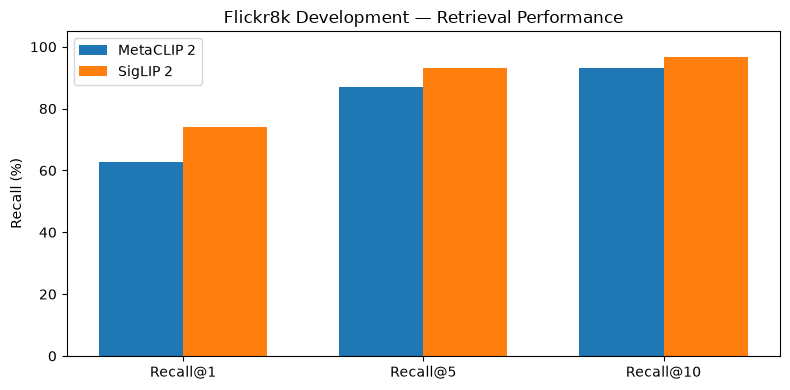

In [14]:
# Compare retrieval accuracy
metrics = ["Recall@1", "Recall@5", "Recall@10"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 4))

plt.bar(x - width/2,
        [metaclip_results[m] for m in metrics],
        width, label="MetaCLIP 2")

plt.bar(x + width/2,
        [siglip_results[m] for m in metrics],
        width, label="SigLIP 2")

plt.xticks(x, metrics)
plt.ylabel("Recall (%)")
plt.ylim(0, 105)
plt.title("Flickr8k Development — Retrieval Performance")
plt.legend()
plt.tight_layout()
plt.show()

### Qualitative Error Analysis

Quantitative metrics measure overall retrieval accuracy but do not explain individual model failures.

This analysis examines text queries where the models produce different retrieval results.

For each example, the ground-truth image is compared with the top-ranked image from MetaCLIP 2 and SigLIP 2.

The objective is to identify whether retrieval errors involve incorrect objects, activities, visual details, or ambiguous descriptions.

A limitation of Recall@K is that a retrieved image may be semantically relevant even when it is not the annotated ground-truth image. Such cases require visual inspection before drawing conclusions.


Queries where SigLIP 2 succeeds but MetaCLIP 2 fails: 947

Query: A woman crouches near three dogs in a field .


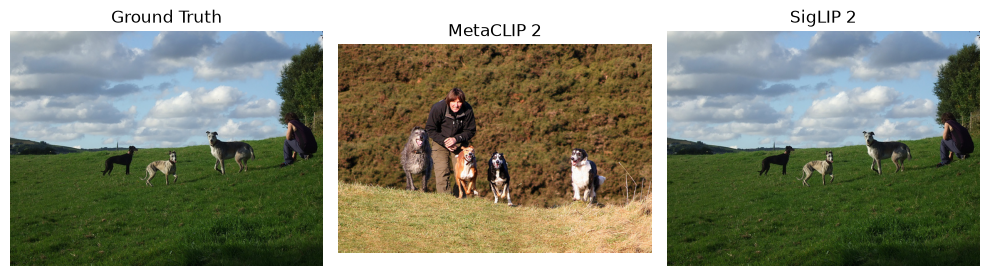


Query: A boy in blue shorts slides down a slide into a pool .


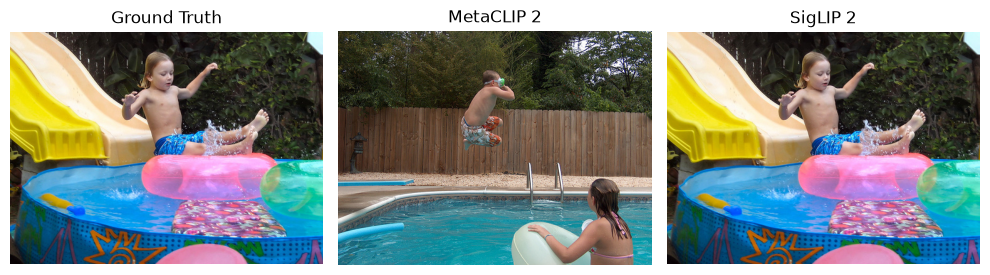

In [15]:
# Identify queries where SigLIP 2 succeeds and MetaCLIP 2 fails

meta_top1 = similarity_scores.argmax(axis=1)
siglip_top1 = siglip_scores.argmax(axis=1)

correct_images = dev_queries["image_id"].to_numpy()

# Queries where only SigLIP 2 retrieves the correct image
improved_cases = np.where(
    (siglip_top1 == correct_images) &
    (meta_top1 != correct_images)
)[0]

print(f"Queries where SigLIP 2 succeeds but MetaCLIP 2 fails: {len(improved_cases):,}")

# Show two examples
for query_id in improved_cases[:2]:
    correct_id = correct_images[query_id]

    print(f"\nQuery: {dev_queries.iloc[query_id]['query']}")

    images = [
        dev_data[int(correct_id)]["image"],
        dev_data[int(meta_top1[query_id])]["image"],
        dev_data[int(siglip_top1[query_id])]["image"]
    ]

    titles = ["Ground Truth", "MetaCLIP 2", "SigLIP 2"]

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))

    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#### Qualitative Finding - Example 1

For the query "A woman crouches near three dogs in a field", SigLIP 2 retrieved the ground-truth image at rank one, whereas MetaCLIP 2 selected a different photograph.

However, MetaCLIP 2's result also contained a woman and several dogs in an outdoor setting, making it semantically relevant despite being marked incorrect.

This highlights a limitation of Recall@K: the metric measures exact ground-truth retrieval rather than the broader usefulness of alternative images.

For Adobe Express, semantic relevance is important because users may find multiple images suitable for the same design description.


MetaCLIP 2 succeeds but SigLIP 2 fails: 374

Query: A baby girl playing at a park .


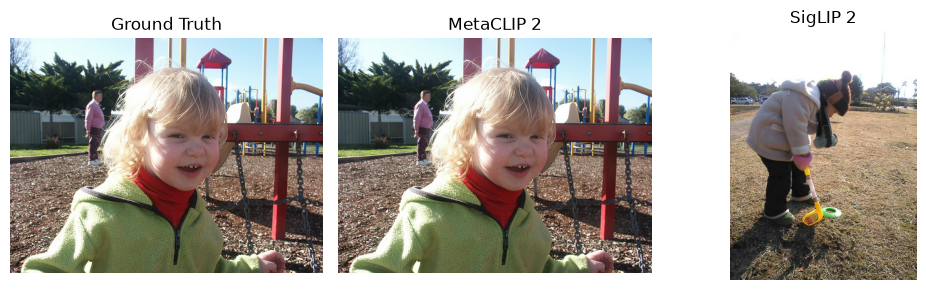

In [16]:
# Find queries where MetaCLIP 2 succeeds but SigLIP 2 fails
meta_better = np.where(
    (meta_top1 == correct_images) &
    (siglip_top1 != correct_images)
)[0]

print(f"MetaCLIP 2 succeeds but SigLIP 2 fails: {len(meta_better):,}")

# Display one example
if len(meta_better) > 0:
    query_id = meta_better[0]

    print("\nQuery:", dev_queries.iloc[query_id]["query"])

    image_ids = [
        correct_images[query_id],
        meta_top1[query_id],
        siglip_top1[query_id]
    ]

    titles = ["Ground Truth", "MetaCLIP 2", "SigLIP 2"]

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))

    for ax, image_id, title in zip(axes, image_ids, titles):
        ax.imshow(dev_data[int(image_id)]["image"])
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#### Qualitative Finding - Example 2

For the query "A baby girl playing at a park", MetaCLIP 2 retrieved the correct playground photograph, while SigLIP 2 selected a different outdoor image.

This example demonstrates that SigLIP 2's higher overall accuracy does not guarantee better performance on every query.

Across the development dataset, SigLIP 2 succeeded where MetaCLIP 2 failed on 947 queries, while MetaCLIP 2 succeeded where SigLIP 2 failed on 374 queries.

The examples also demonstrate that semantic similarity does not always correspond to exact ground-truth retrieval. Both quantitative metrics and visual inspection are therefore necessary to assess retrieval quality.


### Held-Out Test Evaluation

The final retrieval evaluation uses the Flickr8k test split, which contains 1,000 images and five captions per image.

Both pretrained models will be evaluated on the same 5,000 text queries and 1,000 candidate images, using the existing Recall@1, Recall@5, and Recall@10 metrics.

Unlike the development split, the held-out test split provides an independent assessment of retrieval performance.

In [17]:

# Prepare held-out test queries and ground-truth image IDs

test_queries = pd.DataFrame([
    {
        "image_id": image_id,
        "caption_id": caption_id,
        "query": caption
    }
    for caption_id in range(5)
    for image_id, caption in enumerate(
        test_data[f"caption_{caption_id}"]
    )
])

test_ground_truth = test_queries["image_id"].to_numpy()

print(f"Test images: {len(test_data):,}")
print(f"Test queries: {len(test_queries):,}")
print(f"Unique ground-truth images: {test_queries['image_id'].nunique():,}")

display(test_queries.head())


Test images: 1,000
Test queries: 5,000
Unique ground-truth images: 1,000


,image_id,caption_id,query
0,0,0,A blond woman in a blue shirt appears to wait ...
1,1,0,A boy in his blue swim shorts at the beach .
2,2,0,A lady and a man with no shirt sit on a dock .
3,3,0,A closeup of a white dog that is laying its he...
4,4,0,A boy with a toy gun .


**MetaCLIP 2 - Test Image Embeddings**

The pretrained MetaCLIP 2 model is loaded again because it was released from memory during the development evaluation. Image embeddings are extracted from the held-out test split using the same preprocessing, batch size, and normalisation as the development experiment. Inference time is recorded for the efficiency comparison.

In [18]:

# Reload MetaCLIP 2 for held-out test evaluation
model_id = "facebook/metaclip-2-worldwide-b16"

metaclip_processor = AutoProcessor.from_pretrained(model_id)
metaclip_model = AutoModel.from_pretrained(model_id).to(device)
metaclip_model.eval()

# Extract test image embeddings
batch_size = 16
embeddings = []

start_time = time.perf_counter()

for start in range(0, len(test_data), batch_size):
    end = min(start + batch_size, len(test_data))

    images = [
        test_data[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    inputs = metaclip_processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = metaclip_model.get_image_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 128 == 0 or end == len(test_data):
        print(f"Processed {end:,}/{len(test_data):,} images")

metaclip_test_image_embeddings = np.concatenate(
    embeddings, axis=0
)

metaclip_test_image_time = time.perf_counter() - start_time

print("\nMetaCLIP 2 test image extraction complete.")
print("Embedding shape:", metaclip_test_image_embeddings.shape)
print(f"Processing time: {metaclip_test_image_time:.2f} seconds")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 9085.89it/s]


Processed 128/1,000 images
Processed 256/1,000 images
Processed 384/1,000 images
Processed 512/1,000 images
Processed 640/1,000 images
Processed 768/1,000 images
Processed 896/1,000 images
Processed 1,000/1,000 images

MetaCLIP 2 test image extraction complete.
Embedding shape: (1000, 512)
Processing time: 10.40 seconds


In [19]:

# Extract MetaCLIP 2 test caption embeddings

batch_size = 64
captions = test_queries["query"].tolist()
embeddings = []

start_time = time.perf_counter()

for start in range(0, len(captions), batch_size):
    end = min(start + batch_size, len(captions))

    inputs = metaclip_processor(
        text=captions[start:end],
        padding=True,
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = metaclip_model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 640 == 0 or end == len(captions):
        print(f"Processed {end:,}/{len(captions):,} captions")

metaclip_test_text_embeddings = np.concatenate(
    embeddings, axis=0
)

metaclip_test_text_time = time.perf_counter() - start_time

print("\nMetaCLIP 2 test text extraction complete.")
print("Embedding shape:", metaclip_test_text_embeddings.shape)
print(f"Processing time: {metaclip_test_text_time:.2f} seconds")


Processed 640/5,000 captions
Processed 1,280/5,000 captions
Processed 1,920/5,000 captions
Processed 2,560/5,000 captions
Processed 3,200/5,000 captions
Processed 3,840/5,000 captions
Processed 4,480/5,000 captions
Processed 5,000/5,000 captions

MetaCLIP 2 test text extraction complete.
Embedding shape: (5000, 512)
Processing time: 3.22 seconds


In [20]:

# Evaluate MetaCLIP 2 on the held-out test split

metaclip_test_scores = (
    metaclip_test_text_embeddings
    @ metaclip_test_image_embeddings.T
)

metaclip_test_results = evaluate_retrieval(
    metaclip_test_scores,
    test_ground_truth
)

# Display test results
metaclip_test_df = pd.DataFrame([{
    "Model": "MetaCLIP 2",
    **metaclip_test_results
}])

display(metaclip_test_df.round(2))


,Model,Recall@1,Recall@5,Recall@10
0,MetaCLIP 2,62.66,86.24,93.0


In [21]:

# Extract SigLIP 2 test image embeddings

import gc

# Release MetaCLIP 2 after completing its test evaluation
del metaclip_model, metaclip_processor
gc.collect()

if device == "mps":
    torch.mps.empty_cache()

# Load SigLIP 2 if it is not already in memory
if "siglip_model" not in globals():
    from transformers import AutoProcessor, AutoModel

    siglip_id = "google/siglip2-large-patch16-256"
    siglip_processor = AutoProcessor.from_pretrained(siglip_id)
    siglip_model = AutoModel.from_pretrained(siglip_id).to(device)

siglip_model.eval()

batch_size = 16
embeddings = []

start_time = time.perf_counter()

for start in range(0, len(test_data), batch_size):
    end = min(start + batch_size, len(test_data))

    images = [
        test_data[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    inputs = siglip_processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = siglip_model.get_image_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 128 == 0 or end == len(test_data):
        print(f"Processed {end:,}/{len(test_data):,} images")

siglip_test_image_embeddings = np.concatenate(
    embeddings, axis=0
)

siglip_test_image_time = time.perf_counter() - start_time

print("\nSigLIP 2 test image extraction complete.")
print("Embedding shape:", siglip_test_image_embeddings.shape)
print(f"Processing time: {siglip_test_image_time:.2f} seconds")


Processed 128/1,000 images
Processed 256/1,000 images
Processed 384/1,000 images
Processed 512/1,000 images
Processed 640/1,000 images
Processed 768/1,000 images
Processed 896/1,000 images
Processed 1,000/1,000 images

SigLIP 2 test image extraction complete.
Embedding shape: (1000, 1024)
Processing time: 42.98 seconds


In [22]:

# Extract SigLIP 2 test caption embeddings

batch_size = 64
captions = test_queries["query"].tolist()
embeddings = []

start_time = time.perf_counter()

for start in range(0, len(captions), batch_size):
    end = min(start + batch_size, len(captions))

    inputs = siglip_processor(
        text=captions[start:end],
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = siglip_model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    if end % 640 == 0 or end == len(captions):
        print(f"Processed {end:,}/{len(captions):,} captions")

siglip_test_text_embeddings = np.concatenate(
    embeddings, axis=0
)

siglip_test_text_time = time.perf_counter() - start_time

print("\nSigLIP 2 test text extraction complete.")
print("Embedding shape:", siglip_test_text_embeddings.shape)
print(f"Processing time: {siglip_test_text_time:.2f} seconds")


Processed 640/5,000 captions
Processed 1,280/5,000 captions
Processed 1,920/5,000 captions
Processed 2,560/5,000 captions
Processed 3,200/5,000 captions
Processed 3,840/5,000 captions
Processed 4,480/5,000 captions
Processed 5,000/5,000 captions

SigLIP 2 test text extraction complete.
Embedding shape: (5000, 1024)
Processing time: 45.87 seconds


In [23]:

# Evaluate SigLIP 2 on the held-out test split

siglip_test_scores = (
    siglip_test_text_embeddings
    @ siglip_test_image_embeddings.T
)

siglip_test_results = evaluate_retrieval(
    siglip_test_scores,
    test_ground_truth
)

# Compare both models on the held-out test set
test_comparison_df = pd.DataFrame({
    "MetaCLIP 2": metaclip_test_results,
    "SigLIP 2": siglip_test_results
}).T

test_comparison_df.index.name = "Model"

display(test_comparison_df.round(2))


,Recall@1,Recall@5,Recall@10
Model,,,
MetaCLIP 2,62.66,86.24,93.00
SigLIP 2,74.36,93.08,96.92


In [24]:

# Combine held-out retrieval accuracy and inference time

performance_df = test_comparison_df.copy()

performance_df["Image Time (s)"] = [
    metaclip_test_image_time,
    siglip_test_image_time
]

performance_df["Text Time (s)"] = [
    metaclip_test_text_time,
    siglip_test_text_time
]

performance_df["Total Time (s)"] = (
    performance_df["Image Time (s)"]
    + performance_df["Text Time (s)"]
)

display(performance_df.round(2))


,Recall@1,Recall@5,Recall@10,Image Time (s),Text Time (s),Total Time (s)
Model,,,,,,
MetaCLIP 2,62.66,86.24,93.00,10.40,3.22,13.63
SigLIP 2,74.36,93.08,96.92,42.98,45.87,88.85


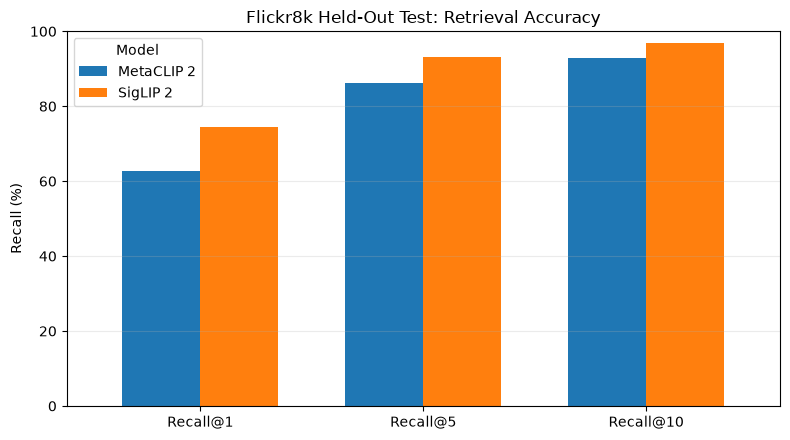

In [25]:

# Visualise held-out test retrieval performance

metrics = ["Recall@1", "Recall@5", "Recall@10"]

ax = test_comparison_df[metrics].T.plot(
    kind="bar",
    figsize=(8, 4.5),
    rot=0,
    width=0.7
)

ax.set_title("Flickr8k Held-Out Test: Retrieval Accuracy")
ax.set_ylabel("Recall (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


### Original Adobe Express Retrieval Evaluation

This experiment evaluates the models using original natural-language search queries representing visual asset discovery tasks in Adobe Express.

The Flickr8k test images serve as a candidate asset library. Suitable images will be selected and assigned manually written search queries, with their image IDs serving as ground-truth labels.

Both models will be evaluated using the same queries and image collection. This is a task-specific supplementary evaluation, not an independent Adobe Express image dataset.

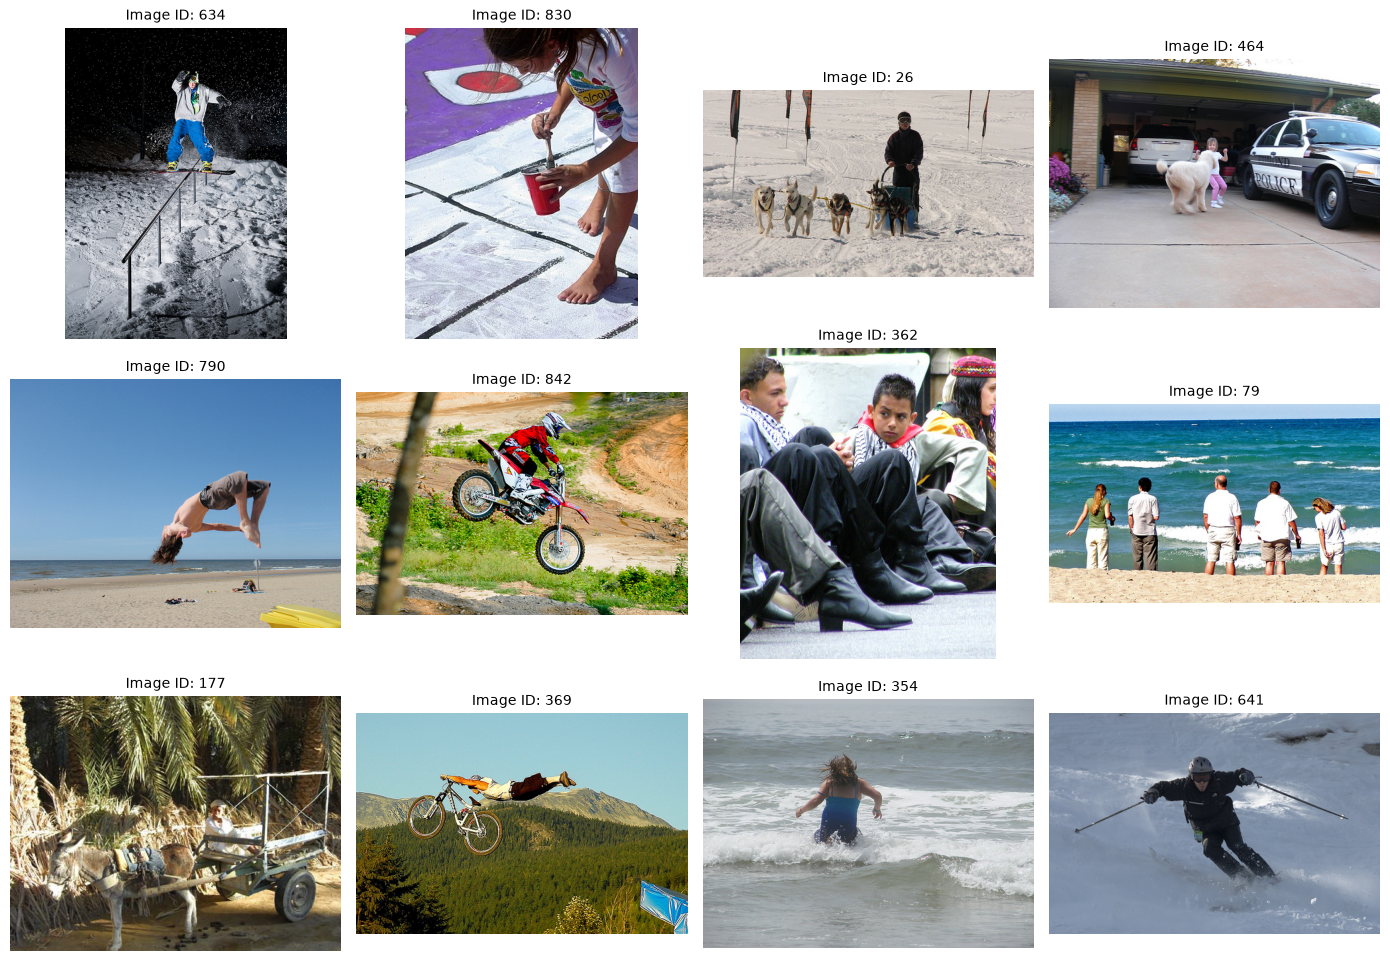

,Image ID,Reference Caption
0,634,A guy on a snowboard grinding .
1,830,A girl bends down to paint something underneat...
2,26,A group of dogs pull a person on a dog sled up...
3,464,A dog corners a little girl next to a police c...
4,790,A boy does a flip on the beach .
5,842,A BMX rider in a red and black outfit is jumpi...
6,362,A boy looks suspiciously at someone nearby .
7,79,A group of people stand in the sand looking ou...
8,177,A donkey pulling a cart with a boy in it takes...
9,369,A bike rider is doing a stunt on a bicycle ove...


In [26]:

# Inspect candidate images for original retrieval cases

rng = np.random.default_rng(2026)

candidate_ids = rng.choice(
    len(test_data),
    size=12,
    replace=False
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, image_id in zip(axes.flat, candidate_ids):
    image = test_data[int(image_id)]["image"]

    ax.imshow(image)
    ax.set_title(f"Image ID: {image_id}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Display reference captions to support image inspection
candidate_df = pd.DataFrame({
    "Image ID": candidate_ids,
    "Reference Caption": [
        test_data[int(i)]["caption_0"]
        for i in candidate_ids
    ]
})

display(candidate_df)


In [39]:

# Original Adobe Express-style retrieval cases
# Image IDs refer to the Flickr8k held-out test split

original_cases = [
    (634, "Nighttime winter sports poster featuring a snowboarder performing a trick on a snowy rail"),
    (830, "Community art workshop promotion showing a young person painting a colourful design on pavement"),
    (26, "Winter adventure advertisement featuring a person travelling with sled dogs across the snow"),
    (464, "Community safety flyer featuring a police car parked outside a family home"),
    (790, "Beach fitness promotion showing a person performing a backflip beside the ocean"),
    (842, "Motocross event poster featuring a rider jumping a dirt bike on a rugged track"),
    (362, "Community gathering photograph showing people sitting together outdoors"),
    (79, "Coastal travel advertisement showing a group of visitors standing beside the sea"),
    (177, "Rural tourism advertisement featuring a donkey and cart surrounded by palm trees"),
    (369, "Extreme mountain biking poster featuring a cyclist airborne above a forested valley"),
    (354, "Summer beach activity advertisement showing a person entering ocean waves"),
    (641, "Winter skiing promotion featuring a skier descending a snowy mountain slope")
]

original_queries = pd.DataFrame(
    original_cases,
    columns=["image_id", "query"]
)

display(original_queries)

print(f"Original evaluation cases: {len(original_queries)}")
print(f"Unique target images: {original_queries['image_id'].nunique()}")


,image_id,query
0,634,Nighttime winter sports poster featuring a sno...
1,830,Community art workshop promotion showing a you...
2,26,Winter adventure advertisement featuring a per...
3,464,Community safety flyer featuring a police car ...
4,790,Beach fitness promotion showing a person perfo...
5,842,Motocross event poster featuring a rider jumpi...
6,362,Community gathering photograph showing people ...
7,79,Coastal travel advertisement showing a group o...
8,177,Rural tourism advertisement featuring a donkey...
9,369,Extreme mountain biking poster featuring a cyc...


Original evaluation cases: 12
Unique target images: 12


In [40]:

# Reload MetaCLIP 2 for the original retrieval evaluation

metaclip_id = "facebook/metaclip-2-worldwide-b16"

metaclip_processor = AutoProcessor.from_pretrained(
    metaclip_id
)

metaclip_model = AutoModel.from_pretrained(
    metaclip_id
).to(device)

metaclip_model.eval()

print("MetaCLIP 2 ready for original retrieval evaluation.")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 8700.02it/s]


MetaCLIP 2 ready for original retrieval evaluation.


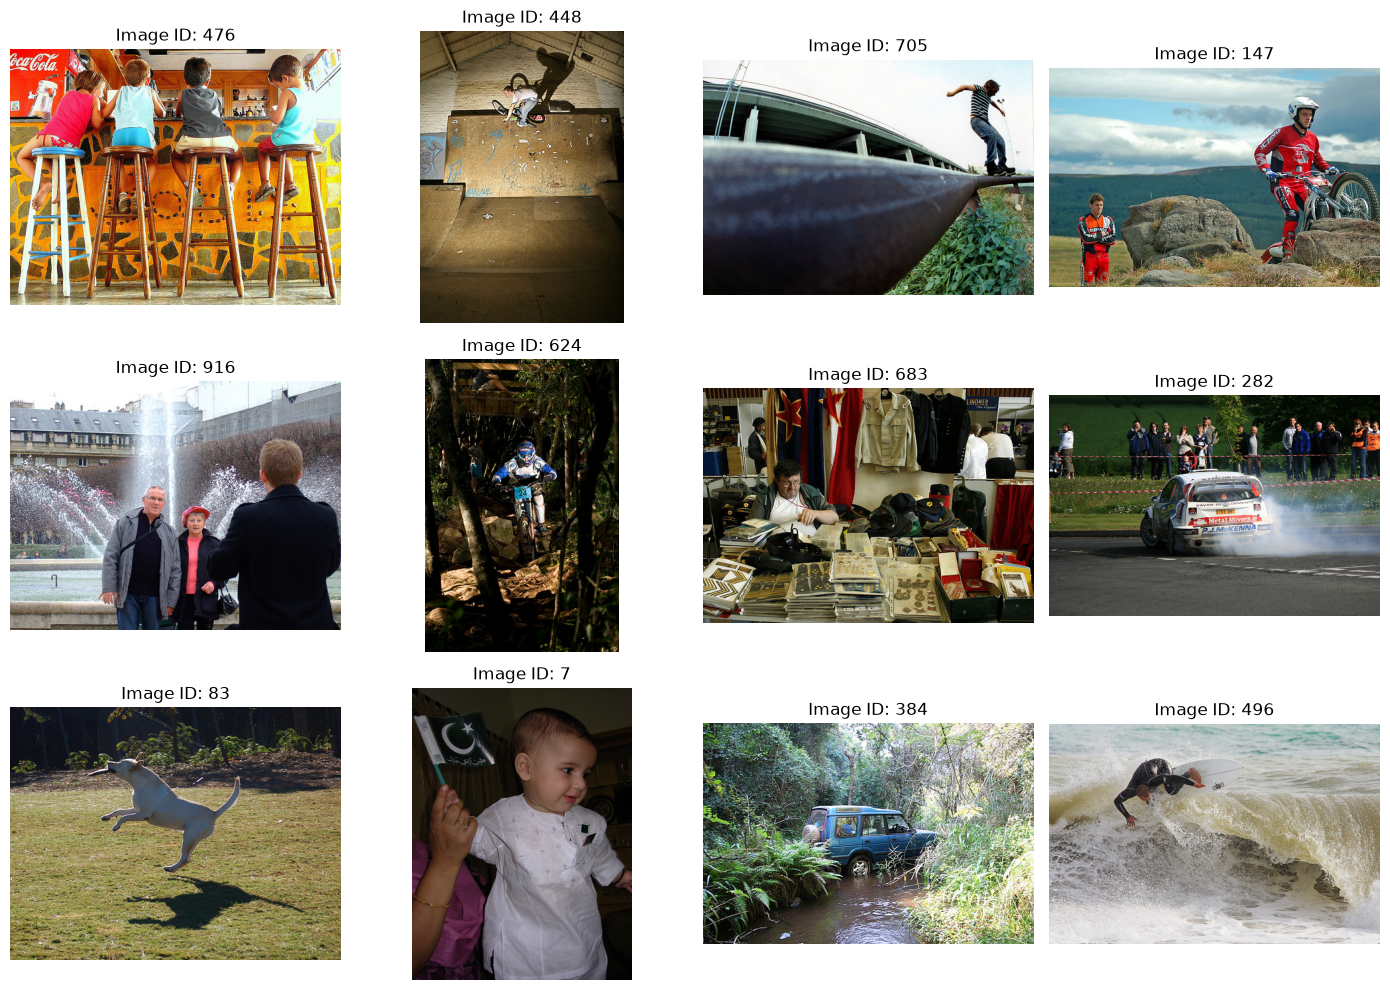

,Image ID,Reference Caption
0,476,Four children on stools in a diner .
1,448,A BMX biker performing a wall-ride on a ramp .
2,705,A boy standing on railing
3,147,A dirt biker pushes his motorcycle up a rock w...
4,916,A couple is photographed in front of a large o...
5,624,A dirt biker in the forest .
6,683,A large man sits in a military accessories sto...
7,282,A race car blows smoke while it drives .
8,83,A dog is jumping to catch a Frisbee and casts ...
9,7,A baby in a white garment holds a flag with cr...


In [41]:

# Inspect additional images for original retrieval cases

rng = np.random.default_rng(2027)

available_ids = np.setdiff1d(
    np.arange(len(test_data)),
    np.array([image_id for image_id, _ in original_cases])
)


additional_ids = rng.choice(
    available_ids,
    size=12,
    replace=False
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, image_id in zip(axes.flat, additional_ids):
    ax.imshow(test_data[int(image_id)]["image"])
    ax.set_title(f"Image ID: {image_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Image ID": additional_ids,
    "Reference Caption": [
        test_data[int(i)]["caption_0"]
        for i in additional_ids
    ]
}))


In [42]:

# Add 12 more Adobe Express-style retrieval cases

additional_cases = [
    (476, "Family restaurant promotion showing children sitting on stools at a colourful cafe counter"),
    (448, "BMX freestyle event advertisement featuring a cyclist performing a trick on an indoor ramp"),
    (705, "Urban lifestyle poster featuring a young person balancing on a metal railing near a bridge"),
    (147, "Motorcycle trials competition poster featuring a rider navigating large rocks on a motorbike"),
    (916, "City tourism advertisement featuring visitors posing beside a large outdoor fountain"),
    (624, "Off-road motorcycle adventure poster featuring a dirt bike rider navigating a wooded trail"),
    (683, "Vintage collectibles market promotion showing a vendor selling military memorabilia, clothing and books"),
    (282, "Motorsport event promotion showing a rally car drifting in front of spectators"),
    (83, "Pet activity advertisement featuring a white dog jumping across a grassy park"),
    (7, "Cultural celebration flyer showing a young child beside a green crescent-and-star flag"),
    (384, "Off-road adventure advertisement featuring a four-wheel-drive vehicle crossing a forest stream"),
    (496, "Surfing competition poster featuring a surfer riding a powerful breaking ocean wave")
]

# Rebuild the complete dataset without duplicating queries
original_queries = pd.DataFrame(
    original_cases + additional_cases,
    columns=["image_id", "query"]
)


print(f"Total original queries: {len(original_queries)}")
print(f"Unique target images: {original_queries['image_id'].nunique()}")

display(original_queries)


Total original queries: 24
Unique target images: 24


,image_id,query
0,634,Nighttime winter sports poster featuring a sno...
1,830,Community art workshop promotion showing a you...
2,26,Winter adventure advertisement featuring a per...
3,464,Community safety flyer featuring a police car ...
4,790,Beach fitness promotion showing a person perfo...
5,842,Motocross event poster featuring a rider jumpi...
6,362,Community gathering photograph showing people ...
7,79,Coastal travel advertisement showing a group o...
8,177,Rural tourism advertisement featuring a donkey...
9,369,Extreme mountain biking poster featuring a cyc...


In [43]:

# Evaluate all 24 original queries with both models

assert len(original_queries) == 24
assert original_queries["image_id"].is_unique

queries = original_queries["query"].tolist()
target_ids = original_queries["image_id"].to_numpy()

# Encode queries using the models already loaded
def encode_original_queries(model, processor, texts, padding):
    inputs = processor(
        text=texts,
        padding=padding,
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    return features.cpu().numpy()


# MetaCLIP 2
metaclip_original_embeddings = encode_original_queries(
    metaclip_model,
    metaclip_processor,
    queries,
    padding=True
)

metaclip_original_scores = (
    metaclip_original_embeddings
    @ metaclip_test_image_embeddings.T
)

# SigLIP 2
siglip_original_embeddings = encode_original_queries(
    siglip_model,
    siglip_processor,
    queries,
    padding="max_length"
)

siglip_original_scores = (
    siglip_original_embeddings
    @ siglip_test_image_embeddings.T
)

# Calculate Recall@K
original_results = {
    "MetaCLIP 2": evaluate_retrieval(
        metaclip_original_scores, target_ids
    ),
    "SigLIP 2": evaluate_retrieval(
        siglip_original_scores, target_ids
    )
}

original_comparison_df = pd.DataFrame(original_results).T
original_comparison_df.index.name = "Model"

print("Adobe Express Retrieval Evaluation — 24 Queries")
display(original_comparison_df.round(2))

# Calculate target image rankings for individual cases
metaclip_ranked = np.argsort(-metaclip_original_scores, axis=1)
siglip_ranked = np.argsort(-siglip_original_scores, axis=1)

original_case_results = original_queries.copy()

original_case_results["MetaCLIP Rank"] = (
    (metaclip_ranked == target_ids[:, None]).argmax(axis=1) + 1
)

original_case_results["SigLIP Rank"] = (
    (siglip_ranked == target_ids[:, None]).argmax(axis=1) + 1
)

display(original_case_results)


Adobe Express Retrieval Evaluation — 24 Queries


,Recall@1,Recall@5,Recall@10
Model,,,
MetaCLIP 2,66.67,91.67,95.83
SigLIP 2,66.67,91.67,100.00


,image_id,query,MetaCLIP Rank,SigLIP Rank
0,634,Nighttime winter sports poster featuring a sno...,1,3
1,830,Community art workshop promotion showing a you...,1,1
2,26,Winter adventure advertisement featuring a per...,1,1
3,464,Community safety flyer featuring a police car ...,1,1
4,790,Beach fitness promotion showing a person perfo...,2,2
5,842,Motocross event poster featuring a rider jumpi...,2,8
6,362,Community gathering photograph showing people ...,2,5
7,79,Coastal travel advertisement showing a group o...,1,1
8,177,Rural tourism advertisement featuring a donkey...,1,1
9,369,Extreme mountain biking poster featuring a cyc...,1,1


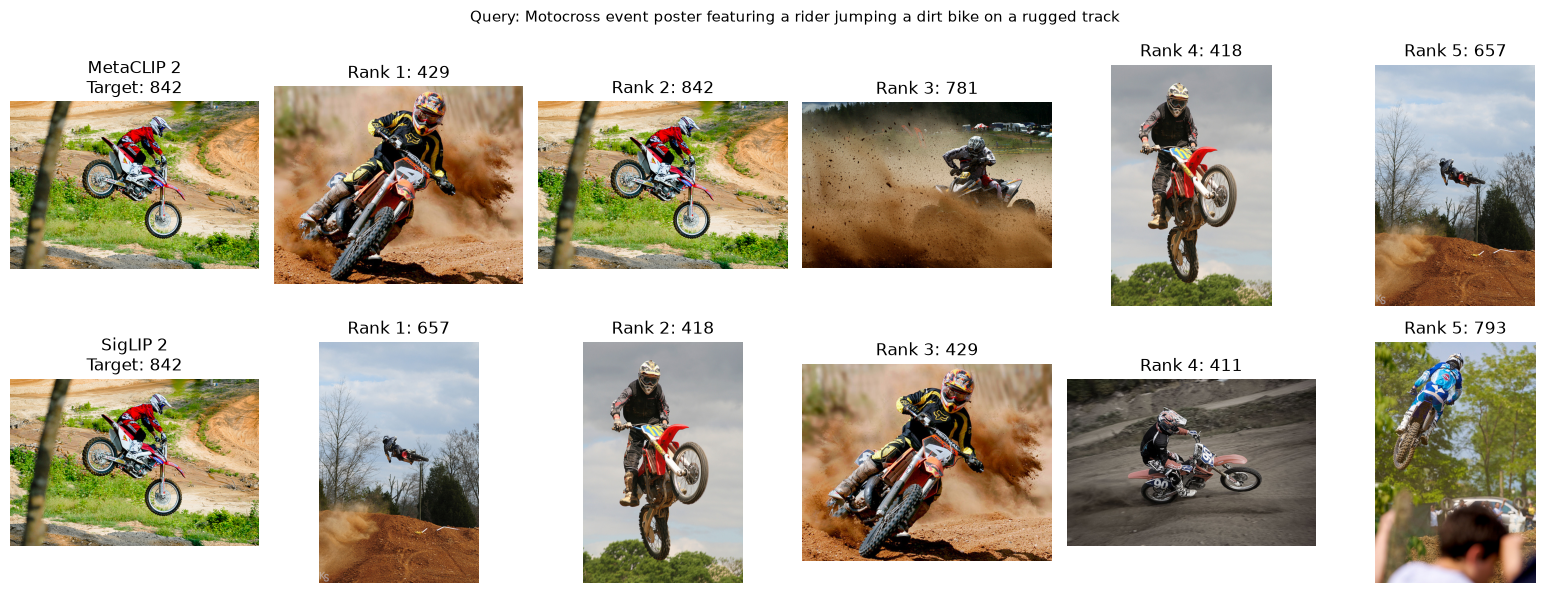

In [44]:

# Inspect retrieval differences for the motocross query

case_index = original_queries.index[
    original_queries["image_id"] == 842
][0]

query = original_queries.loc[case_index, "query"]
target_id = int(original_queries.loc[case_index, "image_id"])

fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for row, (model_name, scores) in enumerate([
    ("MetaCLIP 2", metaclip_original_scores),
    ("SigLIP 2", siglip_original_scores)
]):
    ranked_ids = np.argsort(-scores[case_index])[:5]

    # Ground-truth target
    axes[row, 0].imshow(test_data[target_id]["image"])
    axes[row, 0].set_title(f"{model_name}\nTarget: {target_id}")

    # Top five retrieved images
    for rank, image_id in enumerate(ranked_ids, start=1):
        axes[row, rank].imshow(
            test_data[int(image_id)]["image"]
        )
        axes[row, rank].set_title(
            f"Rank {rank}: {image_id}"
        )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(f"Query: {query}", fontsize=11)
plt.tight_layout()
plt.show()


The motocross example illustrates a limitation of single-target retrieval evaluation. Although MetaCLIP 2 ranked the designated target image second and SigLIP 2 ranked it eighth, both models retrieved semantically relevant alternatives. SigLIP 2's top result also depicts an airborne motocross rider, closely matching the query. Therefore, single-target Recall@K may underestimate retrieval quality when multiple images satisfy a user's search intent. Human relevance assessment would provide a more realistic evaluation for Adobe Express.

The evaluation reveals an accuracy–efficiency trade-off between MetaCLIP 2 and SigLIP 2.

On the Flickr8k held-out test set, SigLIP 2 achieved higher retrieval accuracy, with Recall@1 of 74.36%, compared with 62.66% for MetaCLIP 2. However, MetaCLIP 2 completed image and text feature extraction in 13.63 seconds, compared with 88.85 seconds for SigLIP 2. These are preliminary single-run measurements, not definitive application latency benchmarks.

On the 24 original Adobe Express-style queries, both models achieved Recall@1 of 66.67% and Recall@5 of 91.67%. SigLIP 2 achieved higher Recall@10 (100% versus 95.83%).

Qualitative inspection showed that alternative retrieved images could be relevant even when they were not the designated target. The original queries were created after examining the images, and some descriptions were subsequently corrected. Therefore, this evaluation provides exploratory evidence rather than an independent benchmark.

For the proposed Adobe Express retrieval system, SigLIP 2 is the stronger candidate when benchmark accuracy is prioritised. It also has a more commercially permissive checkpoint licence. MetaCLIP 2 offers faster feature extraction in this experiment, but its selected checkpoint has non-commercial licensing restrictions. Further evaluation using representative design assets, multiple relevance labels, and repeated inference-time measurements is recommended before deployment.